<a href="https://colab.research.google.com/github/IngridM21/ConnetaTell-Analysis/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  


- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)


Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Las siguientes columnas tienen los siguientes porcentajes de datos faltantes: City= 11% , churn_date = 88%, date=0,125%, duration=55%, lenght=44%
- Indica qué harías: ¿imputar, eliminar, ignorar?
- Para la columna `city` imputaria estos datos
- En la columna `churn_date` representa la fecha en que el cliente se dio de baja, lo que signica que los clientes con datos nulos aun siguen activos, por lo cual dejaria la columna tal cual como esta o crearia una nueva donde se represente la actividad del cliente.
- En la columna `date` imputaria estos datos con la media ya que representan un porcentaje minimo de nulos.
- En la columna `duration` y `lenght` dependen de la columna `type` lo que signica que `duration` pertenece a las llamadas y `lenght` a los textos, lo unico que se debe hacer es revisar que valores hacen falta en texto y llamada e imputar o eliminar si el porcentaje es bajo en cada variable.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` es la identificacion de resgistros por lo tanto no se requiere evaluacion estadistica.
- La columna `age` se observa un valor minimo de -999, esto representa un sentinel que se debe corregir mas adelante.

In [ ]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`como se mencionó anteriormente son identificadores de registro y es por ello que no se requiere evaluacioón estadistica.
- Las columnas `duration` muestra valores bajos y `lenght` muestra valores altos.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())
print(users[columnas_user].value_counts(normalize=True))

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595
city      plan   
Bogotá    Basico     0.147833
CDMX      Basico     0.134240
Medellín  Basico     0.112716
GDL       Basico     0.084395
Bogotá    Premium    0.080997
MTY       Basico     0.077882
Cali      Basico     0.074200
CDMX      Premium    0.072501
Medellín  Premium    0.061739
Cali      Premium    0.045879
GDL       Premium    0.043047
MTY       Premium    0.037383
?         Basico     0.018408
          Premium    0.008779
dtype: float64


- La columna `city` muestra que hay 7 ciudades unicas pero una de esas tiene el valor '?' que representa el 1.84% y un espacio en blanco que representa un 0.8%
- La columna `plan` no tiene valores nulos y son solo dos valores unicos

In [ ]:
# explorar columna categórica de usage
print(usage['type'].describe())
print(usage['type'].value_counts(normalize=True))

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object
text    0.5523
call    0.4477
Name: type, dtype: float64


- La columna `type` tiene los valores completos con dos variables unicas ('tex' y 'call')y la mayor frecuciencia y top la tiene la variable text.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels? Se encontraron sentinels (?) y espacio en blanco en la columna `city`
- ¿Qué acción tomarías? se reemplazarían los valores nulos por NA.  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce', utc=True)

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce', utc=True)

In [ ]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se observan datos de los años 2022, 2023, 2024 y 2026.

haz doble clic en este bloque y escribe qué ves.

In [ ]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En `date`, se encuentran 39950 fechas del año 2024, hacen falta 50 datos de fecha.
haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos). Aparecen años futuros como 2026 y años pasados como 2022 y 2023.
- ¿Qué harías con ellas?
- Se deben eliminar las fechas que no son requeridas para el analisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
verificacion_age = (users['age'] == -999).sum()
print(verificacion_age)

0


In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
verificacion_city = (users['city'] == '?').sum()
print(verificacion_city)

0


In [ ]:
# Marcar fechas futuras como NA para reg_date
fecha_limite = pd.Timestamp('2024/12/31', tz='UTC')
users.loc[users['reg_date'] > fecha_limite, 'reg_date']=pd.NA

# Verificar cambios
verificacion_date = users['reg_date'].isna().sum() #se marcaron como nulos 40 fechas futuras que aparecian del año 2026
print(verificacion_date)

40


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending=False)

type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending=False)

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos: En `duration` y `length` estas columnas dependen de las variables `call` y `text` respectivamente esto quiere decir que se dejan los nulos porque son Missing At Random.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamadas`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text': 'cant_mensajes', 'is_call': 'cant_llamadas',
                                      'duration': 'cant_minutos_llamadas'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamadas
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on=['user_id'], how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamadas
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
print(user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']].describe())

               age  cant_mensajes  cant_llamadas  cant_minutos_llamadas
count  4000.000000    3999.000000    3999.000000            3999.000000
mean     48.122250       5.524381       4.478120              23.317054
std      17.690408       2.358416       2.144238              18.168095
min      18.000000       0.000000       0.000000               0.000000
25%      33.000000       4.000000       3.000000              11.120000
50%      47.000000       5.000000       4.000000              19.780000
75%      63.000000       7.000000       6.000000              31.415000
max      79.000000      17.000000      15.000000             155.690000


In [ ]:
# Distribución porcentual del tipo de plan
print(user_profile[['plan']].describe())

          plan
count     4000
unique       2
top     Basico
freq      2595


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

Límites reales de cada barra:
Rango: [18.00 a 23.08] -> Cantidad: 129
Rango: [23.08 a 28.17] -> Cantidad: 127
Rango: [28.17 a 33.25] -> Cantidad: 103
Rango: [33.25 a 38.33] -> Cantidad: 127
Rango: [38.33 a 43.42] -> Cantidad: 117
Rango: [43.42 a 48.50] -> Cantidad: 123
Rango: [48.50 a 53.58] -> Cantidad: 118
Rango: [53.58 a 58.67] -> Cantidad: 100
Rango: [58.67 a 63.75] -> Cantidad: 98
Rango: [63.75 a 68.83] -> Cantidad: 101
Rango: [68.83 a 73.92] -> Cantidad: 108
Rango: [73.92 a 79.00] -> Cantidad: 154
Rango: [18.00 a 23.08] -> Cantidad: 238
Rango: [23.08 a 28.17] -> Cantidad: 201
Rango: [28.17 a 33.25] -> Cantidad: 238
Rango: [33.25 a 38.33] -> Cantidad: 202
Rango: [38.33 a 43.42] -> Cantidad: 224
Rango: [43.42 a 48.50] -> Cantidad: 246
Rango: [48.50 a 53.58] -> Cantidad: 196
Rango: [53.58 a 58.67] -> Cantidad: 220
Rango: [58.67 a 63.75] -> Cantidad: 206
Rango: [63.75 a 68.83] -> Cantidad: 209
Rango: [68.83 a 73.92] -> Cantidad: 184
Rango: [73.92 a 79.00] -> Cantidad: 231


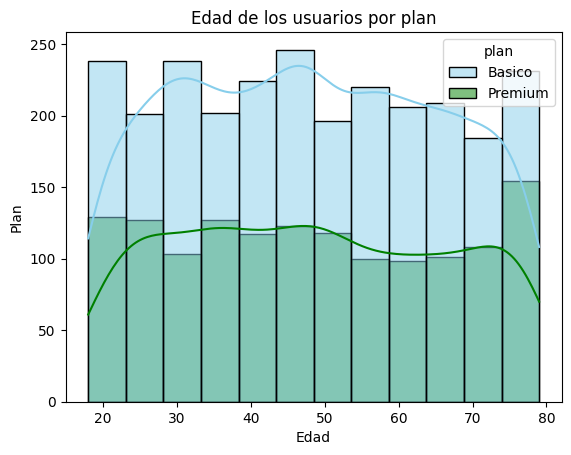

In [ ]:
# Histograma para visualizar la edad (age)
ax = sns.histplot(data=user_profile, x='age', bins=12, hue='plan', palette=['skyblue', 'green'], kde=True)
print("Límites reales de cada barra:")
for patch in ax.patches:
    x_inicio = patch.get_x()
    x_fin = x_inicio + patch.get_width()
    altura = patch.get_height()
    if altura > 0:
        print(f"Rango: [{x_inicio:.2f} a {x_fin:.2f}] -> Cantidad: {int(altura)}")
plt.xlabel('Edad')
plt.ylabel('Plan')
plt.title('Edad de los usuarios por plan')
plt.show()

💡Insights:
- Se observa que en los dos planes hay una distribución relativamente normal o multimodal entre los 18 a 80 años, sin concentración clara en algún grupo de edad. El plan básico predomina el volumen de usuarios en casi todos los rangos de edad. Se observa que ambos planes atraen usuarios de todas las edades por igual, esto sugiere que la edad no es una variable segmentadora para la definición de estrategia comercial de los planes..

Límites reales de cada barra:
Rango: [0.00 a 1.21] -> Cantidad: 34
Rango: [1.21 a 2.43] -> Cantidad: 79
Rango: [2.43 a 3.64] -> Cantidad: 168
Rango: [3.64 a 4.86] -> Cantidad: 224
Rango: [4.86 a 6.07] -> Cantidad: 456
Rango: [6.07 a 7.29] -> Cantidad: 180
Rango: [7.29 a 8.50] -> Cantidad: 114
Rango: [8.50 a 9.71] -> Cantidad: 74
Rango: [9.71 a 10.93] -> Cantidad: 37
Rango: [10.93 a 12.14] -> Cantidad: 30
Rango: [12.14 a 13.36] -> Cantidad: 7
Rango: [13.36 a 14.57] -> Cantidad: 1
Rango: [15.79 a 17.00] -> Cantidad: 1
Rango: [0.00 a 1.21] -> Cantidad: 73
Rango: [1.21 a 2.43] -> Cantidad: 153
Rango: [2.43 a 3.64] -> Cantidad: 294
Rango: [3.64 a 4.86] -> Cantidad: 402
Rango: [4.86 a 6.07] -> Cantidad: 842
Rango: [6.07 a 7.29] -> Cantidad: 329
Rango: [7.29 a 8.50] -> Cantidad: 220
Rango: [8.50 a 9.71] -> Cantidad: 145
Rango: [9.71 a 10.93] -> Cantidad: 72
Rango: [10.93 a 12.14] -> Cantidad: 52
Rango: [12.14 a 13.36] -> Cantidad: 3
Rango: [13.36 a 14.57] -> Cantidad: 4
Rango: [14.57 a 15.79]

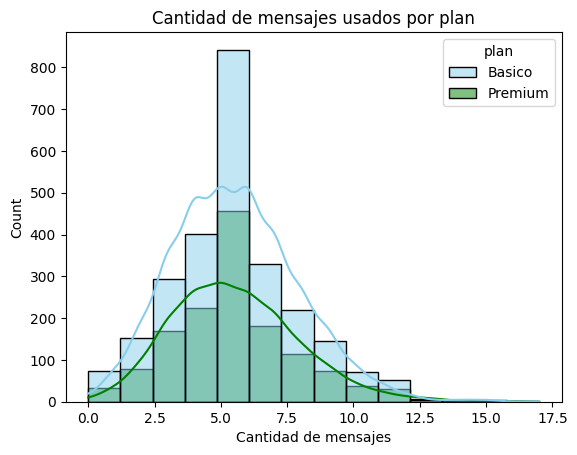

In [ ]:
# Histograma para visualizar la cant_mensajes
ax = sns.histplot(data=user_profile, x='cant_mensajes', bins=14, hue='plan', palette=['skyblue', 'green'], kde=True)
print("Límites reales de cada barra:")
for patch in ax.patches:
    x_inicio = patch.get_x()
    x_fin = x_inicio + patch.get_width()
    altura = patch.get_height()
    if altura > 0:
        print(f"Rango: [{x_inicio:.2f} a {x_fin:.2f}] -> Cantidad: {int(altura)}")
plt.xlabel('Cantidad de mensajes')
plt.title('Cantidad de mensajes usados por plan')
plt.show()


💡Insights:
- Se observa una distribucion aproximadamente normal sesgada ligeramente hacia la derecha, la mayor concentracion en ambos planes envia aproximadamente entre 4 y 7 mensajes alcanzando el pico entre 5 a 6 mesajes. Hay mayor volumen en plan basico, esto quiere decir que hay una cantidad mayor de usuarios registrados y uso en el plan basico en comparacion con el plan premium. En ambos casos se observa que es muy poco comun que algunos usuarios enviaen mas de 12.5 mensajes y en casos extremos 17.5 mensajes.

Límites reales de cada barra:
Rango: [0.00 a 1.25] -> Cantidad: 77
Rango: [1.25 a 2.50] -> Cantidad: 150
Rango: [2.50 a 3.75] -> Cantidad: 264
Rango: [3.75 a 5.00] -> Cantidad: 264
Rango: [5.00 a 6.25] -> Cantidad: 409
Rango: [6.25 a 7.50] -> Cantidad: 104
Rango: [7.50 a 8.75] -> Cantidad: 79
Rango: [8.75 a 10.00] -> Cantidad: 38
Rango: [10.00 a 11.25] -> Cantidad: 20
Rango: [0.00 a 1.25] -> Cantidad: 174
Rango: [1.25 a 2.50] -> Cantidad: 316
Rango: [2.50 a 3.75] -> Cantidad: 432
Rango: [3.75 a 5.00] -> Cantidad: 493
Rango: [5.00 a 6.25] -> Cantidad: 731
Rango: [6.25 a 7.50] -> Cantidad: 232
Rango: [7.50 a 8.75] -> Cantidad: 105
Rango: [8.75 a 10.00] -> Cantidad: 61
Rango: [10.00 a 11.25] -> Cantidad: 40
Rango: [11.25 a 12.50] -> Cantidad: 8
Rango: [12.50 a 13.75] -> Cantidad: 1
Rango: [13.75 a 15.00] -> Cantidad: 1


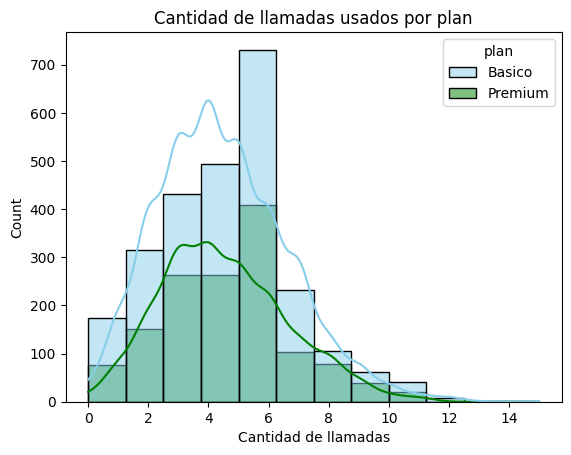

In [ ]:
# Histograma para visualizar la cant_llamadas
ax = sns.histplot(data=user_profile, x='cant_llamadas', bins=12, hue='plan', palette=['skyblue', 'green'], kde=True)
print("Límites reales de cada barra:")
for patch in ax.patches:
    x_inicio = patch.get_x()
    x_fin = x_inicio + patch.get_width()
    altura = patch.get_height()
    if altura > 0:
        print(f"Rango: [{x_inicio:.2f} a {x_fin:.2f}] -> Cantidad: {int(altura)}")
plt.xlabel('Cantidad de llamadas')
plt.title('Cantidad de llamadas usados por plan')
plt.show()

💡Insights:
- La distribución tiene un sesgo hacia la derecha, donde se observa un pico marcado entre 5 y 6 llamadas. El patron de uso de llamadas entre el plan básico y el plan premium es similar, lo que se diferencia es el volumen de los usuarios, donde el básico tiene entre ~730 usuarios del pico. Por ultimo se observa una concentración relevante de 0 llamadas (entre 175 usuarios en básico y entre 75 en premium) que pagan el servicio pero no realizan llamadas.

Límites reales de cada barra:
Rango: [0.00 a 8.19] -> Cantidad: 220
Rango: [8.19 a 16.39] -> Cantidad: 320
Rango: [16.39 a 24.58] -> Cantidad: 315
Rango: [24.58 a 32.78] -> Cantidad: 208
Rango: [32.78 a 40.97] -> Cantidad: 147
Rango: [40.97 a 49.17] -> Cantidad: 107
Rango: [49.17 a 57.36] -> Cantidad: 37
Rango: [57.36 a 65.55] -> Cantidad: 15
Rango: [65.55 a 73.75] -> Cantidad: 15
Rango: [73.75 a 81.94] -> Cantidad: 6
Rango: [81.94 a 90.14] -> Cantidad: 1
Rango: [122.91 a 131.11] -> Cantidad: 2
Rango: [131.11 a 139.30] -> Cantidad: 6
Rango: [139.30 a 147.50] -> Cantidad: 2
Rango: [147.50 a 155.69] -> Cantidad: 4
Rango: [0.00 a 8.19] -> Cantidad: 444
Rango: [8.19 a 16.39] -> Cantidad: 610
Rango: [16.39 a 24.58] -> Cantidad: 565
Rango: [24.58 a 32.78] -> Cantidad: 428
Rango: [32.78 a 40.97] -> Cantidad: 249
Rango: [40.97 a 49.17] -> Cantidad: 137
Rango: [49.17 a 57.36] -> Cantidad: 70
Rango: [57.36 a 65.55] -> Cantidad: 39
Rango: [65.55 a 73.75] -> Cantidad: 17
Rango: [73.75 a 81.94] -> 

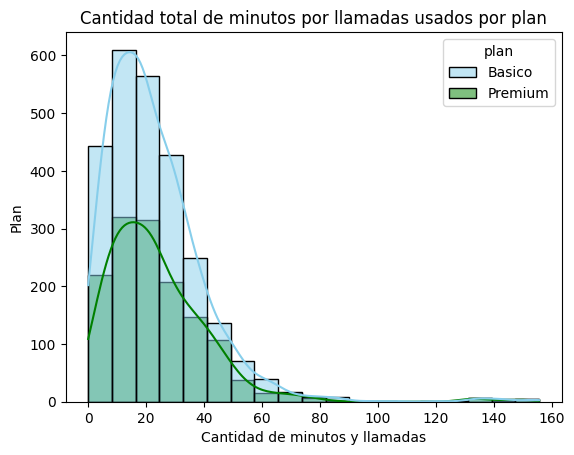

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
ax = sns.histplot(data=user_profile, x='cant_minutos_llamadas', bins=19, hue='plan', palette=['skyblue', 'green'], kde=True)
print("Límites reales de cada barra:")
for patch in ax.patches:
    x_inicio = patch.get_x()
    x_fin = x_inicio + patch.get_width()
    altura = patch.get_height()
    if altura > 0:
        print(f"Rango: [{x_inicio:.2f} a {x_fin:.2f}] -> Cantidad: {int(altura)}")
plt.xlabel('Cantidad de minutos y llamadas')
plt.ylabel('Plan')
plt.title('Cantidad total de minutos por llamadas usados por plan')
plt.show()

💡Insights:
- Se observa una distribución sesgada a la derecha, con la mayoria de los usuarios concentrados entre 0 y 40 minitos/llamadas y una cola larga hasta 160. La forma de consumo es equivalente entre cada plan, se observan algunos casos de uso intensivo pertenecientes al plan básico o con presencia residual del plan premium.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

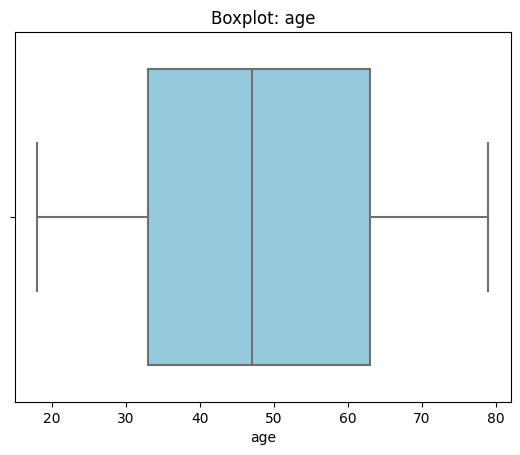

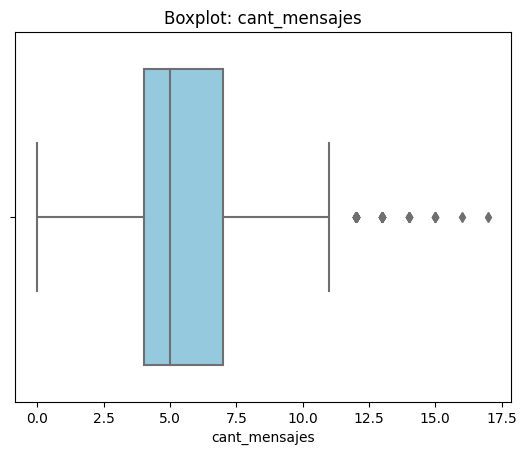

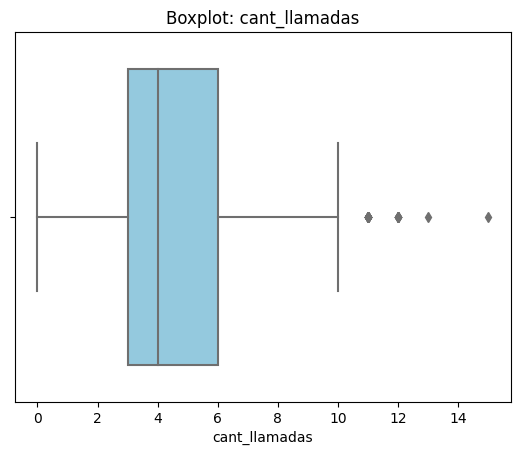

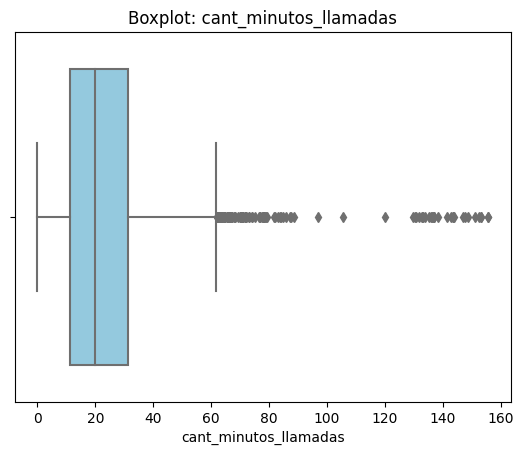

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']


for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col,  color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights:
- Age: no presenta outliers.
- cant_mensajes: presenta outliers pero no en gran proporción.
- cant_llamadas: presenta outliers pero no en gran proporción.
- cant_minutos_llamada: se observa alta cantidad de outliers.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamadas']

limite_superior = {}
for col in columnas_limites :
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior[col] = Q3 + 1.5 * IQR
print(f'Limite superior:', limite_superior)


Limite superior: {'cant_mensajes': 11.5, 'cant_llamadas': 10.5, 'cant_minutos_llamadas': 61.8575}


In [ ]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamadas
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000



💡Insights:
- cant_mensajes, cant_llamadas, cant_minutos_llamada: mantener o no outliers, porqué? se mantienen los outliers en cada uno porque son datos reales registrados por cada cliente, con esta información se pueden crear campañas para los usuarios que tienen una alta cantidad de uso de cada plan.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
def clasificacion_uso (row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']

    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificacion_uso, axis=1)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamadas,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
def clasificacion_edad (row):
    edad = row['age']

    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificacion_edad, axis=1)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamadas,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

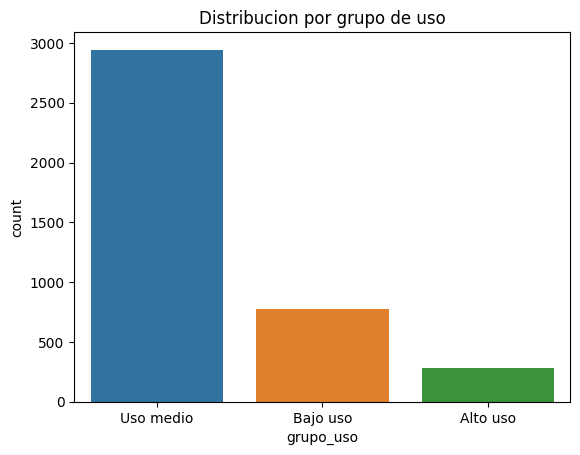

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=user_profile.grupo_uso.value_counts().index)
plt.title('Distribucion por grupo de uso')
plt.show()

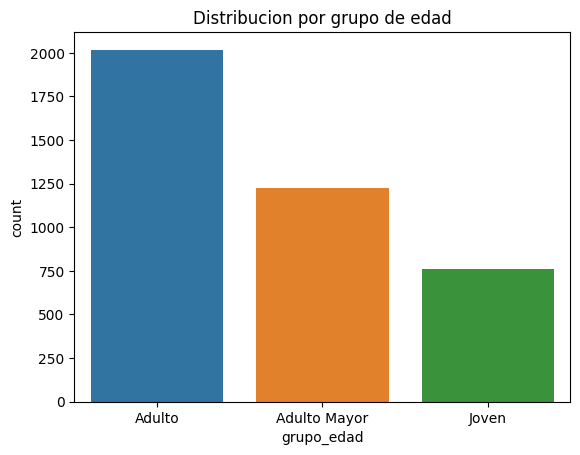

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=user_profile.grupo_edad.value_counts().index)
plt.title('Distribucion por grupo de edad')
plt.show()

In [ ]:
pd.crosstab(user_profile['grupo_uso'], user_profile['grupo_edad'])

grupo_edad,Adulto,Adulto Mayor,Joven
grupo_uso,,,
Alto uso,154,74,51
Bajo uso,364,257,157
Uso medio,1500,891,552



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Se encontraron columnas con datos faltantes las cuales se representan los siguientes porcentajes: City= 11% , churn_date = 88%, date=0,125%, duration=55%, lenght=44%.
- Se encontraron sentinels en la columna age (-999) el cual se reemplazó por la media  y en la columna city ('?' y espacio en blanco) donde se reemplazaron los sentinels por NA.
- La columna 'date' se encontraba en formato object por lo que se procedió a cambiar al formato datetime utc.


🔍 **Segmentos por Edad  y 📊 Segmentos por Nivel de Uso**
- Se identificaron segmentos de clientes por grupo de edad (Adulto, Adulto Mayor y Joven) y por grupo de uso de llamadas y mensajes (Uso alto, Uso medio y Uso bajo). A traves de esta segmentación se encontró que los usuarios de diferentes edades ya sea adulto, adulto mayor o joven tienen un uso medio, seguido de esto un uso bajo y por ultimo un uso alto de llamadas y mensajes respectivamente, esto indica que el nivel de uso no varia segun la edad, aunque el grupo Adulto es el que presenta mas valor con un total de uso (2018), seguido adulto mayor (1222) y los Jovenes (760).


➡️ Esto sugiere que ...


💡 **Recomendaciones**
- Re-segmenetar los planes segun el uso real, con el 73% de usuarios con uso medio, el plan Premium debe esta mal calibrado por lo que se sugiere crear un plan intermedio ($17 o $18 usd), dirigido especificamente al segmento de uso medio, que es donde hay mas usuarios.
- Reservar el plan Premium de $25 usd para los usuarios que tienen Alto uso con beneficios realmente diferenciados (datos ilimitado, prioridad de red, acceso a alguna plataforma aliada como: Netflix, HBO, Disney+, etc).

- identificar los usuarios Premium que llevan 2 o 3 meses en Bajo uso y Uso medio para ofrecerles cambiarse a un plan mas barato como el intermedio que se menciono anteriormente para mantener la fidelizacion u ofrecerles productos de servicios combinados como romaing internacional, soporte prioritario o linea de atencion exclusiva, almacenamiento en la nube entre otros, para justificar el precio y que no solo se limite a mensajes/llamadas y no perder estos usuarios que son los que pagan mas dinero. Cabe recalcar que se debe primero ofrecer los beneficios para mantener el precio original y si el cliente no esta de acuerdo, de ofrece el cambio a un plan mas economico.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`